In [1]:
# ============================================================
# CELL 1 — Setup: Drive, đường dẫn, cấu hình chung, kiểm tra dữ liệu
# Notebook 06: Benchmark 5 kiến trúc ĐƠN NHÃN (softmax)
# ============================================================
import os, json, random
import numpy as np
import tensorflow as tf
from google.colab import drive

# 1. Kết nối Google Drive
drive.mount('/content/drive')

# 2. Đường dẫn (khớp cấu trúc blueprint)
PROJECT_DIR = '/content/drive/MyDrive/flower-multilabel-project'
RAW_DIR     = f'{PROJECT_DIR}/data/raw'
CLASSES_JSON = f'{PROJECT_DIR}/data/metadata/classes.json'
CKPT_DIR    = f'{PROJECT_DIR}/models/checkpoints_singlelabel'   # tách riêng, không đè checkpoint đa nhãn Tuần 3
COMPARE_DIR = f'{PROJECT_DIR}/models/comparison'
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(COMPARE_DIR, exist_ok=True)

# 3. Cấu hình chung — GIỐNG NHAU cho cả 5 kiến trúc (đảm bảo so sánh công bằng)
SEED        = 42
IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
NUM_CLASSES = 10
LR_STAGE1, LR_STAGE2 = 1e-4, 1e-5
MAX_EPOCHS_S1, MAX_EPOCHS_S2 = 20, 15
PATIENCE_S1, PATIENCE_S2 = 4, 3
UNFREEZE_RATIO = 0.30          # mở khóa 30% lớp cuối ở giai đoạn 2
MODEL_IDS = ['mobilenetv2', 'mobilenetv3large', 'efficientnetb0', 'resnet50v2', 'densenet121']

# 4. Cố định seed để tái lập kết quả (NFR-08)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# 5. Đọc classes.json — thứ tự lớp cố định (CON-05)
with open(CLASSES_JSON, encoding='utf-8') as f:
    classes_meta = json.load(f)
print('classes.json:', classes_meta if len(str(classes_meta)) < 600 else '(đã nạp)')

# 6. Kiểm tra dữ liệu data/raw: mỗi thư mục con = 1 lớp
class_ids = sorted(d for d in os.listdir(RAW_DIR) if os.path.isdir(f'{RAW_DIR}/{d}'))
print(f'\nSố lớp tìm thấy trong data/raw: {len(class_ids)}')
total = 0
for c in class_ids:
    n = len([x for x in os.listdir(f'{RAW_DIR}/{c}') if x.lower().endswith(('.jpg', '.jpeg', '.png'))])
    total += n
    print(f'  {c:<18} {n:>5} ảnh')
print(f'Tổng: {total} ảnh (kỳ vọng 5.015)')
assert len(class_ids) == NUM_CLASSES, 'Số lớp không bằng 10 — kiểm tra lại data/raw/'

# 7. Kiểm tra GPU
gpus = tf.config.list_physical_devices('GPU')
print('\nTensorFlow:', tf.__version__)
print('GPU:', gpus if gpus else 'KHÔNG CÓ — vào Runtime > Change runtime type > chọn GPU')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
classes.json: [{'index': 0, 'id': 'hoa_hong', 'name': 'Hoa Hồng'}, {'index': 1, 'id': 'hoa_huong_duong', 'name': 'Hoa Hướng Dương'}, {'index': 2, 'id': 'hoa_cuc', 'name': 'Hoa Cúc'}, {'index': 3, 'id': 'hoa_tulip', 'name': 'Hoa Tulip'}, {'index': 4, 'id': 'hoa_bo_cong_anh', 'name': 'Bồ Công Anh'}, {'index': 5, 'id': 'hoa_sen', 'name': 'Hoa Sen'}, {'index': 6, 'id': 'hoa_lan', 'name': 'Hoa Lan'}, {'index': 7, 'id': 'hoa_mai', 'name': 'Hoa Mai'}, {'index': 8, 'id': 'hoa_dao', 'name': 'Hoa Đào'}, {'index': 9, 'id': 'hoa_oai_huong', 'name': 'Oải Hương'}]

Số lớp tìm thấy trong data/raw: 10
  hoa_bo_cong_anh     1052 ảnh
  hoa_cuc              764 ảnh
  hoa_dao              167 ảnh
  hoa_hong             782 ảnh
  hoa_huong_duong      733 ảnh
  hoa_lan              100 ảnh
  hoa_mai              159 ảnh
  hoa_oai_huong        132 ảnh
  hoa_sen              137 ảnh

In [2]:
# ============================================================
# CELL 2 — Danh sách file + nhãn, chia train/val/test (stratify), class_weight
# ============================================================
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 1. Thứ tự lớp theo classes.json (CON-05) — KHÔNG dùng thứ tự alphabet
CLASS_IDS   = [c['id'] for c in sorted(classes_meta, key=lambda x: x['index'])]
CLASS_NAMES = [c['name'] for c in sorted(classes_meta, key=lambda x: x['index'])]
assert sorted(CLASS_IDS) == class_ids, 'Tên thư mục data/raw không khớp classes.json'

# 2. Gom đường dẫn + nhãn số nguyên (0-9, theo classes.json)
rows = []
for idx, cid in enumerate(CLASS_IDS):
    folder = f'{RAW_DIR}/{cid}'
    for fn in sorted(os.listdir(folder)):
        if fn.lower().endswith(('.jpg', '.jpeg', '.png')):
            rows.append({'path': f'{folder}/{fn}', 'label': idx, 'class_id': cid})
df = pd.DataFrame(rows)
print('Tổng ảnh:', len(df))

# 3. Chia 70/15/15, stratify theo lớp (làm được vì đơn nhãn)
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    d['split'] = name
split_df = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

# 4. Lưu bảng chia tập để cả 5 mô hình + các notebook sau dùng CHUNG đúng 1 split
SPLIT_CSV = f'{PROJECT_DIR}/data/metadata/singlelabel_split.csv'
split_df.to_csv(SPLIT_CSV, index=False)
print('Đã lưu:', SPLIT_CSV)

# 5. Kiểm tra phân bố từng lớp theo tập
dist = pd.crosstab(split_df['class_id'], split_df['split'])[['train', 'val', 'test']]
dist = dist.loc[CLASS_IDS]
print(f'\nTrain/Val/Test = {len(train_df)}/{len(val_df)}/{len(test_df)}')
print(dist)

# 6. Kiểm tra không rò rỉ: không có đường dẫn nào nằm ở 2 tập
assert len(set(train_df.path) & set(val_df.path)) == 0
assert len(set(train_df.path) & set(test_df.path)) == 0
assert len(set(val_df.path) & set(test_df.path)) == 0
print('\nKhông có ảnh nào trùng giữa 3 tập.')

# 7. class_weight (tính CHỈ trên tập train) để bù lớp ít ảnh như hoa_lan
weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_df['label'])
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(weights)}
print('\nclass_weight:')
for i, cid in enumerate(CLASS_IDS):
    print(f'  {i} {cid:<18} {CLASS_WEIGHT[i]:.3f}')

Tổng ảnh: 5010
Đã lưu: /content/drive/MyDrive/flower-multilabel-project/data/metadata/singlelabel_split.csv

Train/Val/Test = 3507/751/752
split            train  val  test
class_id                         
hoa_hong           547  117   118
hoa_huong_duong    513  110   110
hoa_cuc            535  114   115
hoa_tulip          689  147   148
hoa_bo_cong_anh    736  158   158
hoa_sen             96   21    20
hoa_lan             70   15    15
hoa_mai            111   24    24
hoa_dao            117   25    25
hoa_oai_huong       93   20    19

Không có ảnh nào trùng giữa 3 tập.

class_weight:
  0 hoa_hong           0.641
  1 hoa_huong_duong    0.684
  2 hoa_cuc            0.656
  3 hoa_tulip          0.509
  4 hoa_bo_cong_anh    0.476
  5 hoa_sen            3.653
  6 hoa_lan            5.010
  7 hoa_mai            3.159
  8 hoa_dao            2.997
  9 hoa_oai_huong      3.771


In [3]:
# ============================================================
# CELL 3 (bản nhanh) — Nạp toàn bộ ảnh đã cắt vuông + resize vào RAM 1 lần (uint8)
# Sau đó mọi epoch đọc từ RAM, không đọc Drive nữa. Logic cắt/augment GIỮ NGUYÊN.
# ============================================================
import matplotlib.pyplot as plt
AUTOTUNE = tf.data.AUTOTUNE

def load_and_crop(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    h, w = tf.shape(img)[0], tf.shape(img)[1]
    side = tf.minimum(h, w)
    img = tf.image.crop_to_bounding_box(img, (h - side) // 2, (w - side) // 2, side, side)
    img = tf.image.resize(img, IMG_SIZE, method='bilinear')
    return tf.cast(tf.round(img), tf.uint8)          # uint8 để tiết kiệm RAM

def preload(frame, name):
    """Đọc toàn bộ ảnh của 1 tập vào numpy (chỉ tốn thời gian ở lần đầu)."""
    ds = (tf.data.Dataset.from_tensor_slices(frame['path'].values)
          .map(load_and_crop, num_parallel_calls=AUTOTUNE).batch(64).prefetch(AUTOTUNE))
    chunks, n = [], 0
    for b in ds:
        chunks.append(b.numpy()); n += len(b)
        print(f'\r{name}: {n}/{len(frame)}', end='')
    print()
    return np.concatenate(chunks)

CACHE = '/content/cache_224.npz'                      # đĩa cục bộ Colab, không phải Drive
if os.path.exists(CACHE):
    z = np.load(CACHE)
    X_train, X_val, X_test = z['train'], z['val'], z['test']
    print('Nạp từ cache cục bộ.')
else:
    X_train = preload(train_df, 'train')
    X_val   = preload(val_df,   'val')
    X_test  = preload(test_df,  'test')
    np.savez(CACHE, train=X_train, val=X_val, test=X_test)
y_train = tf.keras.utils.to_categorical(train_df['label'].values, NUM_CLASSES)
y_val   = tf.keras.utils.to_categorical(val_df['label'].values,   NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(test_df['label'].values,  NUM_CLASSES)
print('Shape:', X_train.shape, X_val.shape, X_test.shape, '| RAM ~', round((X_train.nbytes+X_val.nbytes+X_test.nbytes)/1e6), 'MB')

# Augmentation nhẹ, chỉ cho train (giữ y hệt bản cũ)
_flip = tf.keras.layers.RandomFlip('horizontal')
_rot  = tf.keras.layers.RandomRotation(15 / 360, fill_mode='reflect')
_zoom = tf.keras.layers.RandomZoom(0.10, fill_mode='reflect')

def augment(img, label):
    img = tf.cast(img, tf.float32)
    img = _flip(img, training=True)
    img = _rot(img, training=True)
    img = _zoom(img, training=True)
    img = tf.image.random_brightness(img, max_delta=30.0)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    return tf.clip_by_value(img, 0.0, 255.0), label

def to_float(img, label):
    return tf.cast(img, tf.float32), label

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
            .map(augment, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds  = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
           .map(to_float, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE))
test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
           .map(to_float, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE))

# --- Kiểm tra ---
xb, yb = next(iter(train_ds))
print('Train batch:', xb.shape, yb.shape, '| pixel', float(tf.reduce_min(xb)), '-', float(tf.reduce_max(xb)))

train: 3507/3507
val: 751/751
test: 752/752
Shape: (3507, 224, 224, 3) (751, 224, 224, 3) (752, 224, 224, 3) | RAM ~ 754 MB
Train batch: (32, 224, 224, 3) (32, 10) | pixel 0.0 - 255.0


In [4]:
# ============================================================
# CELL 4 — build_model(): cùng đầu/đuôi mạng, chỉ đổi base model (softmax)
# preprocess_input RIÊNG của từng kiến trúc được nhúng TRONG model (pixel vào là [0,255])
# ============================================================
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import (MobileNetV2, MobileNetV3Large, EfficientNetB0,
                                           ResNet50V2, DenseNet121)
from tensorflow.keras.applications import (mobilenet_v2, mobilenet_v3, efficientnet,
                                           resnet_v2, densenet)

ARCHS = {
    'mobilenetv2':      (MobileNetV2,      mobilenet_v2.preprocess_input,  'MobileNetV2'),
    'mobilenetv3large': (MobileNetV3Large, mobilenet_v3.preprocess_input,  'MobileNetV3Large'),
    'efficientnetb0':   (EfficientNetB0,   efficientnet.preprocess_input,  'EfficientNetB0'),
    'resnet50v2':       (ResNet50V2,       resnet_v2.preprocess_input,     'ResNet50V2'),
    'densenet121':      (DenseNet121,      densenet.preprocess_input,      'DenseNet121'),
}

def build_model(model_id):
    base_cls, prep, _ = ARCHS[model_id]
    base_model = base_cls(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    base_model.trainable = False                       # Giai đoạn 1: đóng băng

    inputs = layers.Input(shape=(224, 224, 3))
    x = prep(inputs)                                   # chuẩn hóa riêng từng kiến trúc, nằm trong model
    x = base_model(x, training=False)                  # giữ BatchNorm ở chế độ suy luận
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = models.Model(inputs, outputs, name=model_id)

    model.compile(optimizer=optimizers.Adam(LR_STAGE1),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model, base_model

def unfreeze_for_finetune(model, base_model):
    """Giai đoạn 2: mở khóa 30% lớp cuối của base (giống notebook 05), lr = 1e-5."""
    base_model.trainable = True
    fine_tune_at = int(len(base_model.layers) * (1 - UNFREEZE_RATIO))
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False
    model.compile(optimizer=optimizers.Adam(LR_STAGE2),
                  loss='categorical_crossentropy', metrics=['accuracy'])

# --- Kiểm tra nhanh: build thử cả 5, in số tham số và dự đoán thử 1 batch ---
print(f"{'Mô hình':<18}{'Tham số':>14}{'Lớp base':>10}{'Tổng xác suất (≈1)':>22}")
for mid in MODEL_IDS:
    m, b = build_model(mid)
    p = m.predict(xb[:4], verbose=0)
    print(f'{mid:<18}{m.count_params():>14,}{len(b.layers):>10}{p.sum(axis=1).mean():>22.4f}')
    tf.keras.backend.clear_session()

Mô hình                  Tham số  Lớp base    Tổng xác suất (≈1)
mobilenetv2            2,588,490       154                1.0000
mobilenetv3large       3,244,938       187                1.0000
efficientnetb0         4,380,077       238                1.0000
resnet50v2            24,091,914       190                1.0000


densenet121            7,302,474       427                1.0000


In [5]:
# ============================================================
# CELL 5 — Huấn luyện 2 giai đoạn cho 5 kiến trúc (cùng điều kiện, softmax)
# - Lưu checkpoint + history lên Drive sau MỖI giai đoạn
# - Chạy lại cell này sau khi Colab ngắt: mô hình nào đã xong sẽ được bỏ qua
# ============================================================
import time
from tensorflow.keras import callbacks as kcb

MODELS_TO_TRAIN = MODEL_IDS          # có thể rút gọn, vd ['mobilenetv2', 'densenet121'] để chạy từng đợt

def _find_base(model):
    return next(l for l in model.layers if isinstance(l, tf.keras.Model))

def _save_hist(h, path):
    with open(path, 'w') as f:
        json.dump({k: [float(v) for v in vals] for k, vals in h.history.items()}, f)

def train_one(model_id):
    out_dir = f'{CKPT_DIR}/{model_id}'
    os.makedirs(out_dir, exist_ok=True)
    s1_ckpt, s2_ckpt = f'{out_dir}/stage1_best.keras', f'{out_dir}/stage2_best.keras'
    h1_path, h2_path = f'{out_dir}/history_stage1.json', f'{out_dir}/history_stage2.json'

    if os.path.exists(s2_ckpt) and os.path.exists(h2_path):
        print(f'[{model_id}] đã hoàn thành trước đó -> bỏ qua')
        return

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)          # cùng seed cho mọi kiến trúc
    t0 = time.time()

    # ---------- Giai đoạn 1: Feature extraction ----------
    if os.path.exists(s1_ckpt) and os.path.exists(h1_path):
        print(f'[{model_id}] nạp lại kết quả giai đoạn 1')
        model = tf.keras.models.load_model(s1_ckpt)
        base_model = _find_base(model)
    else:
        model, base_model = build_model(model_id)
        cb1 = [kcb.EarlyStopping(monitor='val_loss', patience=PATIENCE_S1, restore_best_weights=True),
               kcb.ModelCheckpoint(s1_ckpt, monitor='val_loss', save_best_only=True)]
        print(f'\n===== {model_id} | GIAI ĐOẠN 1 (tối đa {MAX_EPOCHS_S1} epoch) =====')
        h1 = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS_S1,
                       class_weight=CLASS_WEIGHT, callbacks=cb1, verbose=2)
        _save_hist(h1, h1_path)

    # ---------- Giai đoạn 2: Fine-tuning ----------
    unfreeze_for_finetune(model, base_model)
    cb2 = [kcb.EarlyStopping(monitor='val_loss', patience=PATIENCE_S2, restore_best_weights=True),
           kcb.ModelCheckpoint(s2_ckpt, monitor='val_loss', save_best_only=True)]
    print(f'\n===== {model_id} | GIAI ĐOẠN 2 (tối đa {MAX_EPOCHS_S2} epoch) =====')
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS_S2,
                   class_weight=CLASS_WEIGHT, callbacks=cb2, verbose=2)
    _save_hist(h2, h2_path)

    best_acc = max(h2.history['val_accuracy'])
    print(f'[{model_id}] xong sau {(time.time()-t0)/60:.1f} phút | '
          f'val_loss tốt nhất GĐ2: {min(h2.history["val_loss"]):.4f} | val_acc cao nhất GĐ2: {best_acc:.4f}')

for mid in MODELS_TO_TRAIN:
    train_one(mid)

print('\nĐã xong các mô hình:', [m for m in MODEL_IDS if os.path.exists(f"{CKPT_DIR}/{m}/stage2_best.keras")])

[mobilenetv2] đã hoàn thành trước đó -> bỏ qua
[mobilenetv3large] đã hoàn thành trước đó -> bỏ qua

===== efficientnetb0 | GIAI ĐOẠN 1 (tối đa 20 epoch) =====
Epoch 1/20
110/110 - 109s - 987ms/step - accuracy: 0.4525 - loss: 1.7387 - val_accuracy: 0.7403 - val_loss: 1.1829
Epoch 2/20
110/110 - 40s - 365ms/step - accuracy: 0.7471 - loss: 0.8340 - val_accuracy: 0.7936 - val_loss: 0.7330
Epoch 3/20
110/110 - 41s - 376ms/step - accuracy: 0.8087 - loss: 0.5406 - val_accuracy: 0.8336 - val_loss: 0.5661
Epoch 4/20
110/110 - 39s - 354ms/step - accuracy: 0.8386 - loss: 0.4233 - val_accuracy: 0.8562 - val_loss: 0.4827
Epoch 5/20
110/110 - 39s - 356ms/step - accuracy: 0.8603 - loss: 0.3495 - val_accuracy: 0.8735 - val_loss: 0.4370
Epoch 6/20
110/110 - 40s - 364ms/step - accuracy: 0.8757 - loss: 0.3079 - val_accuracy: 0.8735 - val_loss: 0.4004
Epoch 7/20
110/110 - 39s - 354ms/step - accuracy: 0.8888 - loss: 0.2671 - val_accuracy: 0.8788 - val_loss: 0.3775
Epoch 8/20
110/110 - 38s - 350ms/step - ac

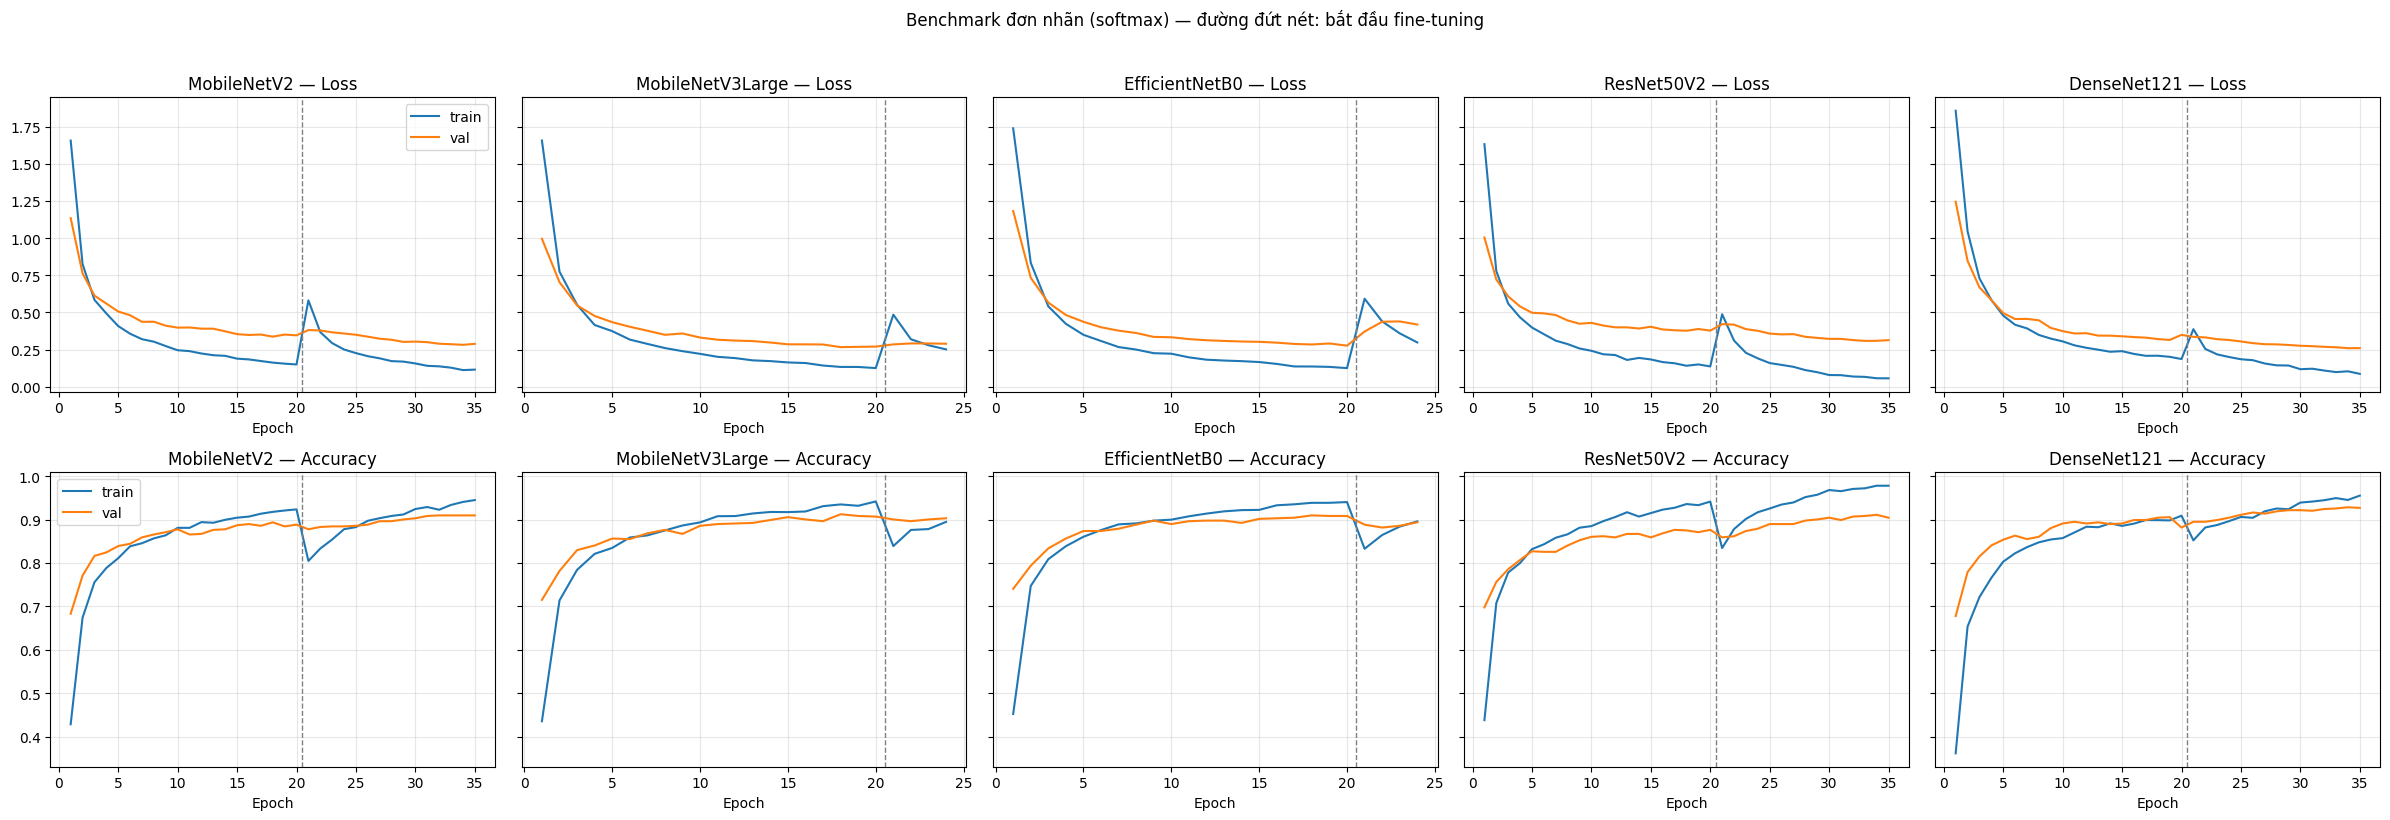

           model  epoch GĐ1  epoch GĐ2  val_loss min  ở epoch  val_acc max  train_acc cuối  val_acc cuối  chênh lệch train-val (acc)
     MobileNetV2         20         15        0.2821       34       0.9095          0.9447        0.9095                      0.0352
MobileNetV3Large         20          4        0.2665       18       0.9121          0.8945        0.9028                     -0.0083
  EfficientNetB0         20          4        0.2762       20       0.9095          0.8956        0.8935                      0.0022
      ResNet50V2         20         15        0.3085       33       0.9108          0.9778        0.9041                      0.0736
     DenseNet121         20         15        0.2595       34       0.9281          0.9549        0.9268                      0.0282


In [6]:
# ============================================================
# CELL 6 — Biểu đồ loss/accuracy 5 mô hình (GĐ1 + GĐ2) + bảng tóm tắt hội tụ
# ============================================================
import matplotlib.pyplot as plt

def load_hist(mid):
    h = {}
    for stage in (1, 2):
        with open(f'{CKPT_DIR}/{mid}/history_stage{stage}.json') as f:
            h[stage] = json.load(f)
    return h

hists = {mid: load_hist(mid) for mid in MODEL_IDS}

fig, axes = plt.subplots(2, 5, figsize=(24, 8), sharey='row')
summary = []
for col, mid in enumerate(MODEL_IDS):
    h1, h2 = hists[mid][1], hists[mid][2]
    n1, n2 = len(h1['loss']), len(h2['loss'])
    tr_loss = h1['loss'] + h2['loss'];         va_loss = h1['val_loss'] + h2['val_loss']
    tr_acc  = h1['accuracy'] + h2['accuracy']; va_acc  = h1['val_accuracy'] + h2['val_accuracy']
    ep = range(1, n1 + n2 + 1)

    for row, (tr, va, ttl) in enumerate([(tr_loss, va_loss, 'Loss'), (tr_acc, va_acc, 'Accuracy')]):
        ax = axes[row, col]
        ax.plot(ep, tr, label='train'); ax.plot(ep, va, label='val')
        ax.axvline(n1 + 0.5, color='gray', ls='--', lw=1)          # ranh giới GĐ1 | GĐ2
        ax.set_title(f'{ARCHS[mid][2]} — {ttl}'); ax.set_xlabel('Epoch'); ax.grid(alpha=.3)
        if col == 0: ax.legend()

    best = int(np.argmin(va_loss))
    summary.append({
        'model': ARCHS[mid][2], 'epoch GĐ1': n1, 'epoch GĐ2': n2,
        'val_loss min': round(min(va_loss), 4), 'ở epoch': best + 1,
        'val_acc max': round(max(va_acc), 4),
        'train_acc cuối': round(tr_acc[-1], 4), 'val_acc cuối': round(va_acc[-1], 4),
        'chênh lệch train-val (acc)': round(tr_acc[-1] - va_acc[-1], 4),
    })
plt.suptitle('Benchmark đơn nhãn (softmax) — đường đứt nét: bắt đầu fine-tuning', y=1.02)
plt.tight_layout(); plt.show()

import pandas as pd
print(pd.DataFrame(summary).to_string(index=False))
fig.savefig(f'{PROJECT_DIR}/reports/weekly_progress/tuan6_singlelabel_curves.png', dpi=150, bbox_inches='tight')

In [7]:
# ============================================================
# CELL 7 — Chọn checkpoint tốt nhất mỗi mô hình (theo val_loss) + đánh giá TEST (1 lần duy nhất)
# ============================================================
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, log_loss, classification_report)

y_val_int  = val_df['label'].values
y_test_int = test_df['label'].values
LABELS = list(range(NUM_CLASSES))

results, test_probs = {}, {}
for mid in MODEL_IDS:
    tf.keras.backend.clear_session()
    cands = {}
    for stage in (1, 2):
        m = tf.keras.models.load_model(f'{CKPT_DIR}/{mid}/stage{stage}_best.keras', compile=False)
        pv = m.predict(val_ds, verbose=0)
        cands[stage] = (log_loss(y_val_int, pv, labels=LABELS), m)
        print(f'[{mid}] stage{stage}_best: val_loss = {cands[stage][0]:.4f}')
    best_stage = min(cands, key=lambda s: cands[s][0])
    val_loss_best, model = cands[best_stage]

    p = model.predict(test_ds, verbose=0)                 # test_ds không shuffle -> khớp test_df
    pred = p.argmax(axis=1)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test_int, pred, labels=LABELS, average='macro', zero_division=0)
    pc_prec, pc_rec, pc_f1, _ = precision_recall_fscore_support(y_test_int, pred, labels=LABELS, zero_division=0)
    results[mid] = {
        'name': ARCHS[mid][2], 'checkpoint': f'stage{best_stage}_best',
        'val_loss': float(val_loss_best),
        'test_accuracy': float(accuracy_score(y_test_int, pred)),
        'test_precision_macro': float(prec), 'test_recall_macro': float(rec), 'test_f1_macro': float(f1),
        'test_auc_ovr_macro': float(roc_auc_score(y_test_int, p, multi_class='ovr', average='macro', labels=LABELS)),
        'per_class_f1': {CLASS_IDS[i]: float(pc_f1[i]) for i in LABELS},
        'per_class_recall': {CLASS_IDS[i]: float(pc_rec[i]) for i in LABELS},
    }
    test_probs[mid] = p
    print(f'[{mid}] chọn stage{best_stage} | test acc {results[mid]["test_accuracy"]:.4f} | F1 macro {f1:.4f}\n')

# Lưu kết quả thô (không mất khi Colab ngắt)
with open(f'{COMPARE_DIR}/singlelabel_test_results.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

# Bảng tổng hợp, sắp theo macro F1
tbl = pd.DataFrame(results).T[['name', 'checkpoint', 'val_loss', 'test_accuracy',
                               'test_precision_macro', 'test_recall_macro', 'test_f1_macro', 'test_auc_ovr_macro']]
tbl = tbl.sort_values('test_f1_macro', ascending=False)
print(tbl.round(4).to_string(index=False))

# F1 từng lớp (để xem lớp ít ảnh như hoa_lan, hoa_oai_huong)
print('\nF1 theo từng lớp:')
print(pd.DataFrame({r['name']: r['per_class_f1'] for r in results.values()}).round(3))

[mobilenetv2] stage1_best: val_loss = 0.3387
[mobilenetv2] stage2_best: val_loss = 0.2830
[mobilenetv2] chọn stage2 | test acc 0.9003 | F1 macro 0.9051

[mobilenetv3large] stage1_best: val_loss = 0.2668
[mobilenetv3large] stage2_best: val_loss = 0.2858
[mobilenetv3large] chọn stage1 | test acc 0.9136 | F1 macro 0.9258

[efficientnetb0] stage1_best: val_loss = 0.2762
[efficientnetb0] stage2_best: val_loss = 0.3716
[efficientnetb0] chọn stage1 | test acc 0.9229 | F1 macro 0.9158

[resnet50v2] stage1_best: val_loss = 0.3767
[resnet50v2] stage2_best: val_loss = 0.3085
[resnet50v2] chọn stage2 | test acc 0.9136 | F1 macro 0.9304

[densenet121] stage1_best: val_loss = 0.3149
[densenet121] stage2_best: val_loss = 0.2595
[densenet121] chọn stage2 | test acc 0.9375 | F1 macro 0.9473

            name  checkpoint  val_loss test_accuracy test_precision_macro test_recall_macro test_f1_macro test_auc_ovr_macro
     DenseNet121 stage2_best  0.259502        0.9375             0.939353          0.9562

Mô hình thắng: DenseNet121 | checkpoint: stage2_best

                 precision    recall  f1-score   support

       Hoa Hồng      0.886     0.924     0.905       118
Hoa Hướng Dương      0.930     0.964     0.946       110
        Hoa Cúc      0.964     0.922     0.942       115
      Hoa Tulip      0.923     0.892     0.907       148
    Bồ Công Anh      0.981     0.956     0.968       158
        Hoa Sen      0.952     1.000     0.976        20
        Hoa Lan      1.000     1.000     1.000        15
        Hoa Mai      0.885     0.958     0.920        24
        Hoa Đào      0.926     1.000     0.962        25
      Oải Hương      0.947     0.947     0.947        19

       accuracy                          0.938       752
      macro avg      0.939     0.956     0.947       752
   weighted avg      0.938     0.938     0.938       752



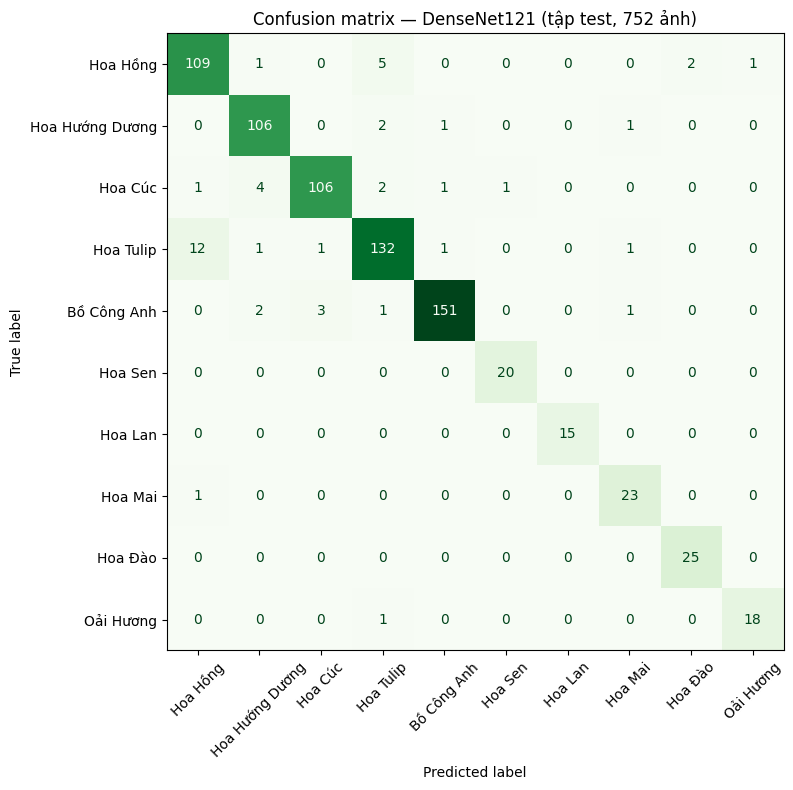

Đã ghi: /content/drive/MyDrive/flower-multilabel-project/models/comparison/model_comparison.json
Đã ghi: /content/drive/MyDrive/flower-multilabel-project/backend/model_comparison.json
Đã xuất: /content/drive/MyDrive/flower-multilabel-project/models/final/flower_singlelabel_model.keras


In [8]:
# ============================================================
# CELL 8 — Chốt mô hình thắng (macro F1 test), confusion matrix, xuất model + model_comparison.json
# ============================================================
import shutil
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Mô hình thắng theo tiêu chí đã chốt: macro F1 trên tập test
winner = max(results, key=lambda m: results[m]['test_f1_macro'])
print('Mô hình thắng:', results[winner]['name'], '| checkpoint:', results[winner]['checkpoint'])

# 2. Báo cáo per-class + confusion matrix của mô hình thắng
pred_w = test_probs[winner].argmax(axis=1)
print('\n' + classification_report(y_test_int, pred_w, target_names=CLASS_NAMES, digits=3, zero_division=0))

cm = confusion_matrix(y_test_int, pred_w, labels=LABELS)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Greens', xticks_rotation=45, colorbar=False)
ax.set_title(f'Confusion matrix — {results[winner]["name"]} (tập test, {len(y_test_int)} ảnh)')
plt.tight_layout()
fig.savefig(f'{PROJECT_DIR}/reports/weekly_progress/tuan6_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Sao lưu file cũ TRƯỚC khi ghi đè (chỉ sao lưu 1 lần)
FINAL_DIR = f'{PROJECT_DIR}/models/final'
final_path = f'{FINAL_DIR}/flower_singlelabel_model.keras'
old_model_bak = f'{FINAL_DIR}/flower_singlelabel_model_nb05.keras'
if os.path.exists(final_path) and not os.path.exists(old_model_bak):
    shutil.copy(final_path, old_model_bak)
old_cmp = f'{COMPARE_DIR}/model_comparison.json'
old_cmp_bak = f'{COMPARE_DIR}/model_comparison_multilabel_week3.json'
if os.path.exists(old_cmp) and not os.path.exists(old_cmp_bak):
    shutil.copy(old_cmp, old_cmp_bak)

# 4. Xuất mô hình thắng
shutil.copy(f'{CKPT_DIR}/{winner}/{results[winner]["checkpoint"]}.keras', final_path)

# 5. model_comparison.json mới. GIỮ tên khóa cũ (val_accuracy, val_auc, precision, recall) để
#    script.js/index.html không phải sửa; giá trị là chỉ số trên TẬP TEST (xem "evaluated_on").
order = ['mobilenetv2', 'mobilenetv3large', 'efficientnetb0', 'resnet50v2', 'densenet121']
comparison = {'models': [{
    'id': mid, 'name': results[mid]['name'],
    'val_accuracy': results[mid]['test_accuracy'],
    'val_auc': results[mid]['test_auc_ovr_macro'],
    'precision': results[mid]['test_precision_macro'],
    'recall': results[mid]['test_recall_macro'],
    'f1_macro': results[mid]['test_f1_macro'],
    'checkpoint': f'models/checkpoints_singlelabel/{mid}/{results[mid]["checkpoint"]}.keras',
    'evaluated_on': 'test', 'task': 'single-label softmax',
    'is_selected': mid == winner,
} for mid in order]}
assert sum(m['is_selected'] for m in comparison['models']) == 1

for dest in (f'{COMPARE_DIR}/model_comparison.json', f'{PROJECT_DIR}/backend/model_comparison.json'):
    with open(dest, 'w', encoding='utf-8') as f:
        json.dump(comparison, f, ensure_ascii=False, indent=2)
    print('Đã ghi:', dest)
print('Đã xuất:', final_path)